In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (2823, 25)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.00000,2823.000000
mean,10258.725115,35.092809,83.658544,6.466171,3553.889072,2.717676,7.092455,2003.81509,100.715551
std,92.085478,9.741443,20.174277,4.225841,1841.865106,1.203878,3.656633,0.69967,40.187912
min,10100.000000,6.000000,26.880000,1.000000,482.130000,1.000000,1.000000,2003.00000,33.000000
25%,10180.000000,27.000000,68.860000,3.000000,2203.430000,2.000000,4.000000,2003.00000,68.000000
50%,10262.000000,35.000000,95.700000,6.000000,3184.800000,3.000000,8.000000,2004.00000,99.000000
75%,10333.500000,43.000000,100.000000,9.000000,4508.000000,4.000000,11.000000,2004.00000,124.000000
max,10425.000000,97.000000,100.000000,18.000000,14082.800000,4.000000,12.000000,2005.00000,214.000000


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

Duplicate Records: 0


In [5]:
customer_data = df.groupby("CUSTOMERNAME").agg(
    TotalQuantity=("QUANTITYORDERED", "sum"),
    AveragePrice=("PRICEEACH", "mean"),
    TotalSales=("SALES", "sum"),
    AverageMSRP=("MSRP", "mean"),
    NumberOfOrders=("ORDERNUMBER", "nunique")
).reset_index()

print("Customer Dataset Shape:", customer_data.shape)

customer_data.head()

Customer Dataset Shape: (92, 6)


,CUSTOMERNAME,TotalQuantity,AveragePrice,TotalSales,AverageMSRP,NumberOfOrders
0,"AV Stores, Co.",1778,77.947647,157807.81,92.843137,3
1,Alpha Cognac,687,85.097500,70488.44,97.150000,3
2,Amica Models & Co.,843,85.323462,94117.26,107.653846,2
3,"Anna's Decorations, Ltd",1469,83.558043,153996.13,104.717391,4
4,Atelier graphique,270,79.775714,24179.96,95.571429,3


In [6]:
X = customer_data[[
    "TotalQuantity",
    "AveragePrice",
    "TotalSales",
    "AverageMSRP",
    "NumberOfOrders"
]]

X.head()

,TotalQuantity,AveragePrice,TotalSales,AverageMSRP,NumberOfOrders
0,1778,77.947647,157807.81,92.843137,3
1,687,85.097500,70488.44,97.150000,3
2,843,85.323462,94117.26,107.653846,2
3,1469,83.558043,153996.13,104.717391,4
4,270,79.775714,24179.96,95.571429,3


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[ 0.6360107  -1.75306058  0.44443187 -0.9772982  -0.1158306 ]
 [-0.35358247  0.34006081 -0.35149724 -0.44117387 -0.1158306 ]
 [-0.21208244  0.40621111 -0.13611702  0.86635965 -0.45958594]
 [ 0.35573179 -0.11061551  0.40968783  0.50082563  0.22792473]
 [-0.73182294 -1.21789341 -0.77360596 -0.63767666 -0.1158306 ]]


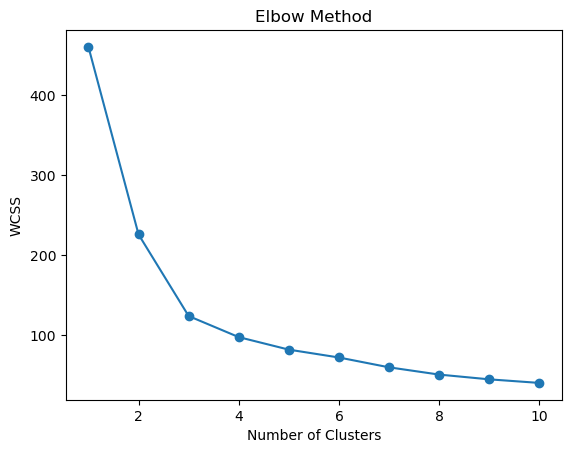

In [8]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [9]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

customer_data["Cluster"] = kmeans.fit_predict(X_scaled)

customer_data.head()

,CUSTOMERNAME,TotalQuantity,AveragePrice,TotalSales,AverageMSRP,NumberOfOrders,Cluster
0,"AV Stores, Co.",1778,77.947647,157807.81,92.843137,3,0
1,Alpha Cognac,687,85.097500,70488.44,97.150000,3,0
2,Amica Models & Co.,843,85.323462,94117.26,107.653846,2,2
3,"Anna's Decorations, Ltd",1469,83.558043,153996.13,104.717391,4,2
4,Atelier graphique,270,79.775714,24179.96,95.571429,3,0


In [10]:
print("Customers in Each Cluster:")
print(customer_data["Cluster"].value_counts())

Customers in Each Cluster:
Cluster
0    50
2    40
1     2
Name: count, dtype: int64


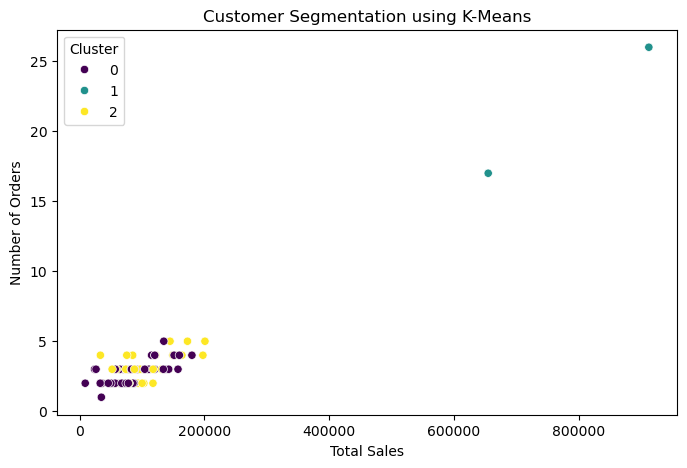

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=customer_data["TotalSales"],
    y=customer_data["NumberOfOrders"],
    hue=customer_data["Cluster"],
    palette="viridis"
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Total Sales")
plt.ylabel("Number of Orders")
plt.show()

In [12]:
print(customer_data.groupby("Cluster")[[
    "TotalQuantity",
    "AveragePrice",
    "TotalSales",
    "AverageMSRP",
    "NumberOfOrders"
]].mean())

         TotalQuantity  AveragePrice    TotalSales  AverageMSRP  \
Cluster                                                           
0               910.40     81.850539   86818.94020    94.947417   
1              7846.50     82.575233  783576.08500    99.760500   
2               946.35     86.610619  103113.24175   107.924121   

         NumberOfOrders  
Cluster                  
0                 2.780  
1                21.500  
2                 3.125  


In [13]:
print("Customer Segmentation using K-Means")
print("-----------------------------------")

print("Total Customers:", len(customer_data))
print("Number of Clusters:", customer_data["Cluster"].nunique())

print("\nCluster Counts:")
print(customer_data["Cluster"].value_counts())

print("\nCluster Analysis:")
print(customer_data.groupby("Cluster")[[
    "TotalQuantity",
    "AveragePrice",
    "TotalSales",
    "AverageMSRP",
    "NumberOfOrders"
]].mean())

Customer Segmentation using K-Means
-----------------------------------
Total Customers: 92
Number of Clusters: 3

Cluster Counts:
Cluster
0    50
2    40
1     2
Name: count, dtype: int64

Cluster Analysis:
         TotalQuantity  AveragePrice    TotalSales  AverageMSRP  \
Cluster                                                           
0               910.40     81.850539   86818.94020    94.947417   
1              7846.50     82.575233  783576.08500    99.760500   
2               946.35     86.610619  103113.24175   107.924121   

         NumberOfOrders  
Cluster                  
0                 2.780  
1                21.500  
2                 3.125  


In [14]:

# PRACTICAL 5: CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING
#
# 1. INTRODUCTION
#
# Customer segmentation is an unsupervised machine learning technique
# used to divide customers into groups based on similar characteristics
# and purchasing behaviour.
#
# Businesses use customer segmentation to understand their customers,
# identify high-value customers, improve marketing strategies,
# provide personalized offers and increase customer satisfaction.
#
# In this practical, K-Means clustering is applied to the
# sales_data_sample.csv dataset to group customers based on their
# purchasing behaviour.
#
# 2. DATASET DESCRIPTION
#
# The dataset used is sales_data_sample.csv.
#
# It contains sales transaction information such as:
# - CUSTOMERNAME: Name of the customer.
# - ORDERNUMBER: Unique order number.
# - QUANTITYORDERED: Quantity of products ordered.
# - PRICEEACH: Price of each product.
# - SALES: Total sales amount.
# - MSRP: Manufacturer's suggested retail price.
#
# The original dataset contains individual transaction records.
# For meaningful customer segmentation, transaction records are
# aggregated at the customer level.
#
# 3. DATA PREPROCESSING AND CUSTOMER AGGREGATION
#
# Data preprocessing is performed to prepare the dataset for clustering.
#
# First, the dataset is loaded using Pandas. The encoding parameter
# may be set to latin1 to handle special characters in the dataset.
#
# Customer-level aggregation is performed using CUSTOMERNAME as the
# grouping column. This converts multiple transaction records into
# one summarized record for each customer.
#
# The following features are calculated:
#
# 1. TotalQuantity:
#    Total number of products ordered by a customer.
#
# 2. AveragePrice:
#    Average price of products purchased by a customer.
#
# 3. TotalSales:
#    Total amount spent by a customer.
#
# 4. AverageMSRP:
#    Average manufacturer's suggested retail price of products.
#
# 5. NumberOfOrders:
#    Number of unique orders placed by a customer.
#
# This aggregation ensures that clustering is performed on customers
# rather than individual sales transactions.
#
# The resulting dataset contains one row per customer and five
# numerical features used for clustering.
#
# 4. INTRODUCTION TO UNSUPERVISED LEARNING
#
# Unsupervised learning is a type of machine learning in which a model
# learns patterns from data without using predefined target labels.
#
# Unlike supervised learning, there is no dependent variable or
# known output during training.
#
# Clustering is an unsupervised learning technique that groups
# similar data points together.
#
# Examples of clustering applications include:
# - Customer segmentation.
# - Document grouping.
# - Image segmentation.
# - Market analysis.
# - Recommendation systems.
#
# 5. K-MEANS CLUSTERING
#
# K-Means is an unsupervised machine learning algorithm used to
# divide a dataset into K distinct clusters.
#
# Each cluster has a centroid, which represents the mean position
# of all data points belonging to that cluster.
#
# The algorithm attempts to place similar data points in the same
# cluster while keeping different clusters separate.
#
# WORKING OF K-MEANS:
#
# Step 1: Select the number of clusters K.
#
# Step 2: Initialize K centroids, generally selected from the data.
#
# Step 3: Calculate the distance between each data point and
#         all cluster centroids.
#
# Step 4: Assign each data point to its nearest centroid.
#
# Step 5: Recalculate the centroid of each cluster by taking
#         the mean of all points assigned to that cluster.
#
# Step 6: Repeat the assignment and centroid update steps until
#         the cluster assignments stop changing or convergence
#         is reached.
#
# 6. IMPORTANCE OF FEATURE SCALING
#
# The five customer features have different numerical ranges.
# For example, TotalSales may have much larger values than AveragePrice.
#
# K-Means uses distance calculations. Features with larger numerical
# ranges can dominate the distance calculation if scaling is not used.
#
# Therefore, StandardScaler is applied before clustering.
#
# Standardization transforms features so that they have approximately
# zero mean and unit standard deviation.
#
# Formula:
#
#       Z = (X - Mean) / Standard Deviation
#
# Where:
# X                  = Original feature value
# Mean               = Mean of the feature
# Standard Deviation = Standard deviation of the feature
# Z                  = Standardized feature value
#
# Scaling ensures that all features contribute more fairly
# to the distance calculation.
#
# 7. ELBOW METHOD FOR OPTIMAL NUMBER OF CLUSTERS
#
# Selecting the correct number of clusters K is important.
# A very small K may combine different customer groups, while
# a very large K may create unnecessary clusters.
#
# The Elbow Method is used to estimate a suitable value of K.
#
# It calculates the Within-Cluster Sum of Squares (WCSS), also
# called inertia, for different values of K.
#
# WCSS measures the sum of squared distances between each data
# point and the centroid of its assigned cluster.
#
# Formula:
#
#       WCSS = Sum of (Distance between point and centroid)^2
#
# The algorithm is executed for different K values, generally
# from 1 to 10.
#
# A graph is plotted with:
# - X-axis: Number of clusters (K).
# - Y-axis: WCSS or inertia.
#
# As K increases, WCSS decreases because data points are divided
# into more clusters.
#
# The optimal K is estimated by identifying the elbow point,
# where the reduction in WCSS starts becoming less significant.
#
# In this practical, the Elbow Method is used to select K = 3.
#
# 8. MODEL IMPLEMENTATION
#
# After selecting the number of clusters, the K-Means model is
# initialized with the following parameters:
#
# - n_clusters = 3
# - random_state = 42
# - n_init = 10
#
# n_clusters specifies the number of groups to create.
#
# random_state ensures reproducible results by controlling
# the random initialization.
#
# n_init specifies the number of times the algorithm is run
# with different centroid initializations.
#
# The model is fitted on the standardized customer features.
# Each customer is assigned a cluster label: 0, 1 or 2.
#
# These labels represent the customer groups discovered by
# the clustering algorithm. They do not represent predefined
# customer categories.
#
# 9. CLUSTER VISUALIZATION AND ANALYSIS
#
# After clustering, the results are visualized using a scatter plot.
#
# The scatter plot uses:
# - X-axis: NumberOfOrders.
# - Y-axis: TotalSales.
# - Different colours: Different cluster labels.
#
# Each point represents one customer.
# Customers belonging to the same cluster are shown using
# the same colour.
#
# Cluster analysis can also be performed by calculating the
# mean values of the features for each cluster.
#
# This helps understand the purchasing behaviour of each group.
#
# For example:
# - Customers with high TotalSales may represent high-value buyers.
# - Customers with many orders may represent frequent buyers.
# - Customers with lower sales and fewer orders may represent
#   less active customers.
#
# These interpretations should be based on the actual cluster
# averages rather than assuming that cluster numbers have a
# fixed meaning.
#
# 10. ADVANTAGES OF K-MEANS
#
# 1. Simple and easy to understand.
# 2. Efficient for datasets with numerical features.
# 3. Can handle a relatively large number of data points.
# 4. Produces clearly defined cluster assignments.
# 5. Useful for customer segmentation and market analysis.
#
# 11. LIMITATIONS OF K-MEANS
#
# 1. The number of clusters K must be selected in advance.
# 2. Results can depend on the initial centroid positions.
# 3. Sensitive to outliers and feature scaling.
# 4. Works best when clusters are reasonably compact and
#    approximately spherical.
# 5. It is mainly suitable for numerical data.
#
# 12. CONCLUSION
#
# In this practical, customer segmentation is performed using
# K-Means clustering on the sales_data_sample.csv dataset.
#
# Transaction records are aggregated by CUSTOMERNAME to create
# customer-level features such as TotalQuantity, AveragePrice,
# TotalSales, AverageMSRP and NumberOfOrders.
#
# StandardScaler is used to normalize the features.
# The Elbow Method is applied to estimate the optimal number
# of clusters, and K-Means is implemented with three clusters.
#
# Finally, customers are assigned to clusters and the results
# are visualized using a scatter plot.
#
# Thus, K-Means helps identify groups of customers with similar
# purchasing behaviour and supports data-driven business decisions.
